In [25]:

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout 

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

In [26]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

with tf.device("/GPU:0"):
    a = tf.random.normal((2048, 2048))
    b = tf.random.normal((2048, 2048))
    result = tf.matmul(a, b)

print("Result device:", result.device)

TensorFlow: 2.10.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Result device: /job:localhost/replica:0/task:0/device:GPU:0


In [27]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

print("Path to dataset files:", path)
data_path = path
print("Using dataset path:", data_path)

Path to dataset files: C:\Users\Ahnaf\.cache\kagglehub\datasets\bhavikjikadara\dog-and-cat-classification-dataset\versions\1
Using dataset path: C:\Users\Ahnaf\.cache\kagglehub\datasets\bhavikjikadara\dog-and-cat-classification-dataset\versions\1


In [28]:
import os

dataset_path = "/kaggle/input/dog-and-cat-classification-dataset"

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:10])
    print("Number of files:", len(files))
    print("Sample files:", files[:5])
    print("-" * 50)

In [29]:
from pathlib import Path

dataset_path = Path(
    "/kaggle/input/dog-and-cat-classification-dataset"
)

# Find folders named Cat/Cats and Dog/Dogs
class_pairs = []

for path in dataset_path.rglob("*"):
    if path.is_dir():
        children = {
            p.name.lower(): p
            for p in path.iterdir()
            if p.is_dir()
        }

        cat_dir = next(
            (children[n] for n in ["cat", "cats"] if n in children),
            None
        )
        dog_dir = next(
            (children[n] for n in ["dog", "dogs"] if n in children),
            None
        )

        if cat_dir and dog_dir:
            class_pairs.append((path, cat_dir, dog_dir))

if not class_pairs:
    # Use the actual path returned by kagglehub
    dataset_path = Path(data_path)
    class_pairs = []

    for parent in [dataset_path] + list(dataset_path.rglob("*")):
        if not parent.is_dir():
            continue

        children = {
            child.name.casefold(): child
            for child in parent.iterdir()
            if child.is_dir()
        }

        cat_dir = next(
            (children[name] for name in ("cat", "cats") if name in children),
            None,
        )
        dog_dir = next(
            (children[name] for name in ("dog", "dogs") if name in children),
            None,
        )

        if cat_dir and dog_dir:
            class_pairs.append((parent, cat_dir, dog_dir))

    if not class_pairs:
        raise FileNotFoundError(
            f"Could not find Cat and Dog folders under: {dataset_path}"
        )

data_dir = str(class_pairs[0][0])

print("Dataset directory:", data_dir)
for parent, cat_dir, dog_dir in class_pairs:
    print("Cat folder:", cat_dir)
    print("Dog folder:", dog_dir)

Dataset directory: C:\Users\Ahnaf\.cache\kagglehub\datasets\bhavikjikadara\dog-and-cat-classification-dataset\versions\1\PetImages
Cat folder: C:\Users\Ahnaf\.cache\kagglehub\datasets\bhavikjikadara\dog-and-cat-classification-dataset\versions\1\PetImages\Cat
Dog folder: C:\Users\Ahnaf\.cache\kagglehub\datasets\bhavikjikadara\dog-and-cat-classification-dataset\versions\1\PetImages\Dog


In [30]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"]
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    class_names=["Cat", "Dog"]
)

print("Classes:", train_ds.class_names)

Found 24998 files belonging to 2 classes.
Using 17499 files for training.
Found 24998 files belonging to 2 classes.
Using 7499 files for validation.
Classes: ['Cat', 'Dog']


In [31]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

val_ds = val_ds.map(
    lambda images, labels: (
        normalization_layer(images), labels
    )
)

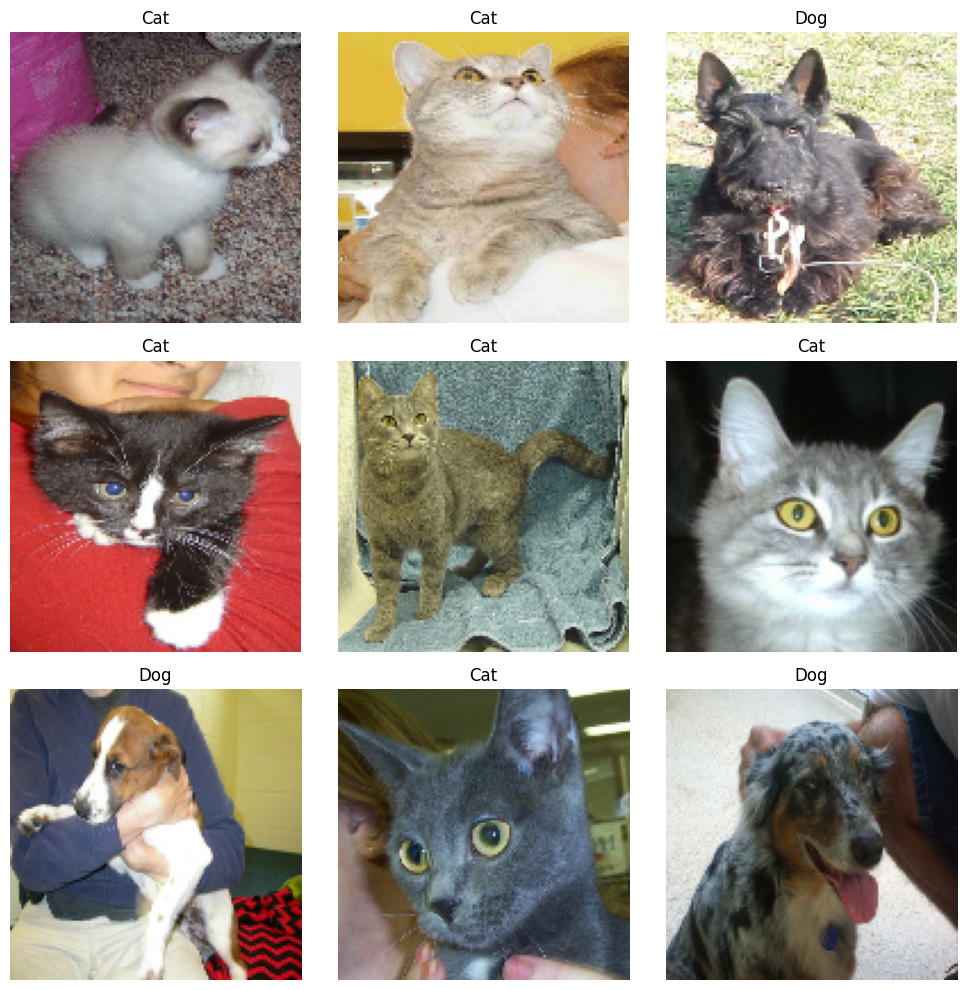

In [32]:
class_names = ["Cat", "Dog"]

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy())

        label = int(labels[i].numpy()[0])
        plt.title(class_names[label])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Images shape: (32, 128, 128, 3)
Labels shape: (32, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [34]:
autotune = tf.data.AUTOTUNE

# Skip image files that TensorFlow cannot decode.
train_ds = train_ds.apply(tf.data.experimental.ignore_errors())
val_ds = val_ds.apply(tf.data.experimental.ignore_errors())

train_ds = train_ds.prefetch(buffer_size=autotune)
val_ds = val_ds.prefetch(buffer_size=autotune)

In [35]:
cnn = Sequential([
    tf.keras.Input(shape=(*IMG_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    Conv2D(32, kernel_size=(3, 3), activation="relu"),
    MaxPool2D(pool_size=(2, 2)),
    Conv2D(64, kernel_size=(3, 3), activation="relu"),
    MaxPool2D(pool_size=(2, 2)),
    tf.keras.layers.GlobalAveragePooling2D(),
    Dense(
        128,
        activation="relu",
        kernel_regularizer=tf.keras.regularizers.l2(1e-4),
    ),
    Dropout(0.5),
    Dense(1, activation="sigmoid"),
])
cnn.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 random_flip (RandomFlip)    (None, 128, 128, 3)       0         
                                                                 
 random_rotation (RandomRota  (None, 128, 128, 3)      0         
 tion)                                                           
                                                                 
 random_zoom (RandomZoom)    (None, 128, 128, 3)       0         
                                                                 
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        1

In [36]:
cnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [37]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True,
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-6,
)

history = cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping, reduce_lr],
)

Epoch 1/5
    255/Unknown - 234s 905ms/step - loss: 0.6947 - accuracy: 0.5228

KeyboardInterrupt: 

In [ ]:
acc_cnn=cnn.evaluate(val_ds,verbose=0)[1]
acc_cnn

0.6459543704986572

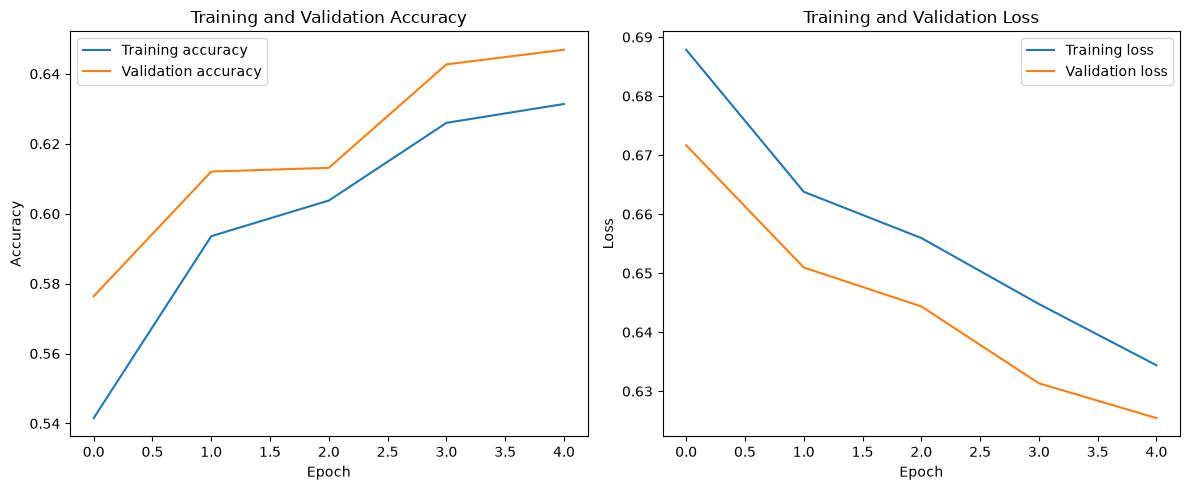

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

resnet_train_ds = train_ds.map(
    lambda images, labels: (preprocess_input(images * 255.0), labels),
    num_parallel_calls=autotune,
).prefetch(autotune)

resnet_val_ds = val_ds.map(
    lambda images, labels: (preprocess_input(images * 255.0), labels),
    num_parallel_calls=autotune,
).prefetch(autotune)

In [ ]:
resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3),
)
resnet_base.trainable = False

resnet50 = tf.keras.Sequential([
    tf.keras.Input(shape=(*IMG_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    resnet_base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
resnet50.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_3 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 4, 4, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │         2,049 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,589,761 (89.99 MB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

In [ ]:
resnet_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

resnet_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
)

history_resnet = resnet50.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=5,
    callbacks=[resnet_early_stopping, resnet_reduce_lr],
)

Epoch 1/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 253s 458ms/step - accuracy: 0.7845 - loss: 0.5631 - val_accuracy: 0.9483 - val_loss: 0.1287 - learning_rate: 1.0000e-04
Epoch 2/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 257s 474ms/step - accuracy: 0.8975 - loss: 0.2818 - val_accuracy: 0.9566 - val_loss: 0.1066 - learning_rate: 1.0000e-04
Epoch 3/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 262s 482ms/step - accuracy: 0.9157 - loss: 0.2254 - val_accuracy: 0.9602 - val_loss: 0.1002 - learning_rate: 1.0000e-04
Epoch 4/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 254s 467ms/step - accuracy: 0.9233 - loss: 0.2047 - val_accuracy: 0.9639 - val_loss: 0.0947 - learning_rate: 1.0000e-04
Epoch 5/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 248s 456ms/step - accuracy: 0.9285 - loss: 0.1907 - val_accuracy: 0.9656 - val_loss: 0.0910 - learning_rate: 1.0000e-04


In [ ]:
acc_resnet = resnet50.evaluate(resnet_val_ds, verbose=0)[1]
print(f"ResNet50 validation accuracy: {acc_resnet:.4f}")

ResNet50 validation accuracy: 0.9656


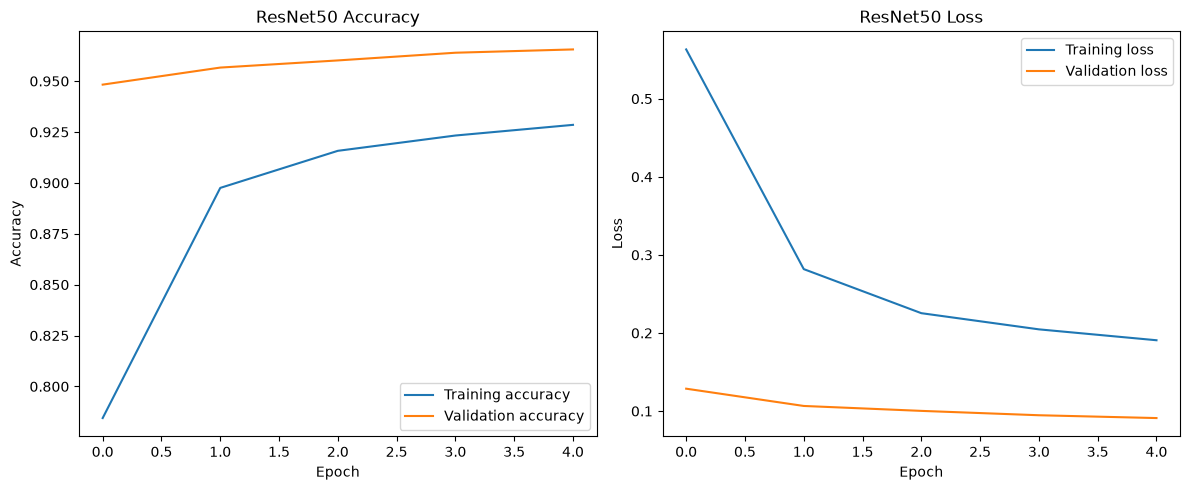

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history["accuracy"], label="Training accuracy")
plt.plot(history_resnet.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history["loss"], label="Training loss")
plt.plot(history_resnet.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Fine-tune the last 20 layers of the pretrained ResNet50 base
resnet_base.trainable = True

for layer in resnet_base.layers[:-20]:
    layer.trainable = False

# Keep BatchNormalization statistics stable during fine-tuning
for layer in resnet_base.layers[-20:]:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

resnet50.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

print("Trainable ResNet50 layers:", sum(layer.trainable for layer in resnet_base.layers))

Trainable ResNet50 layers: 14


In [ ]:
resnet_finetune_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)

resnet_finetune_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
)

history_resnet_finetune = resnet50.fit(
    resnet_train_ds,
    validation_data=resnet_val_ds,
    epochs=5,
    callbacks=[resnet_finetune_early_stopping, resnet_finetune_reduce_lr],
)

acc_resnet_finetune = resnet50.evaluate(resnet_val_ds, verbose=0)[1]
print(f"Fine-tuned ResNet50 validation accuracy: {acc_resnet_finetune:.4f}")

Epoch 1/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 292s 530ms/step - accuracy: 0.9401 - loss: 0.1491 - val_accuracy: 0.9719 - val_loss: 0.0761 - learning_rate: 1.0000e-05
Epoch 2/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 287s 528ms/step - accuracy: 0.9554 - loss: 0.1145 - val_accuracy: 0.9728 - val_loss: 0.0731 - learning_rate: 1.0000e-05
Epoch 3/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 297s 546ms/step - accuracy: 0.9605 - loss: 0.0984 - val_accuracy: 0.9722 - val_loss: 0.0750 - learning_rate: 1.0000e-05
Epoch 4/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 293s 540ms/step - accuracy: 0.9651 - loss: 0.0871 - val_accuracy: 0.9743 - val_loss: 0.0712 - learning_rate: 1.0000e-05
Epoch 5/5
543/543 ━━━━━━━━━━━━━━━━━━━━ 301s 555ms/step - accuracy: 0.9700 - loss: 0.0753 - val_accuracy: 0.9769 - val_loss: 0.0692 - learning_rate: 1.0000e-05
Fine-tuned ResNet50 validation accuracy: 0.9768


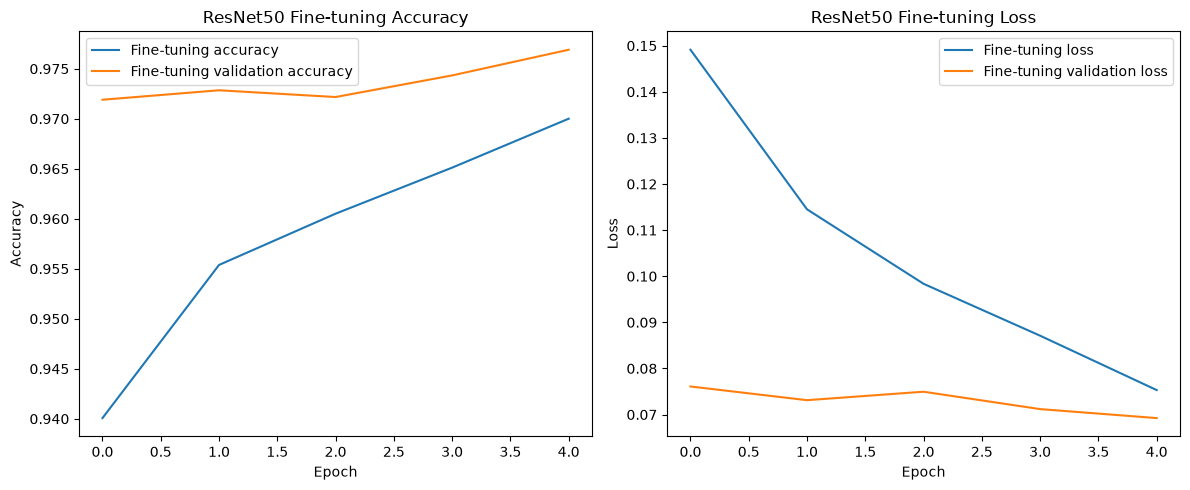

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history_resnet_finetune.history["accuracy"],
    label="Fine-tuning accuracy",
)
plt.plot(
    history_resnet_finetune.history["val_accuracy"],
    label="Fine-tuning validation accuracy",
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet50 Fine-tuning Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    history_resnet_finetune.history["loss"],
    label="Fine-tuning loss",
)
plt.plot(
    history_resnet_finetune.history["val_loss"],
    label="Fine-tuning validation loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Fine-tuning Loss")
plt.legend()

plt.tight_layout()
plt.show()

                       Model  Validation Accuracy (%)
                  Custom CNN                    64.60
ResNet50 without fine-tuning                    96.56
   ResNet50 with fine-tuning                    97.68


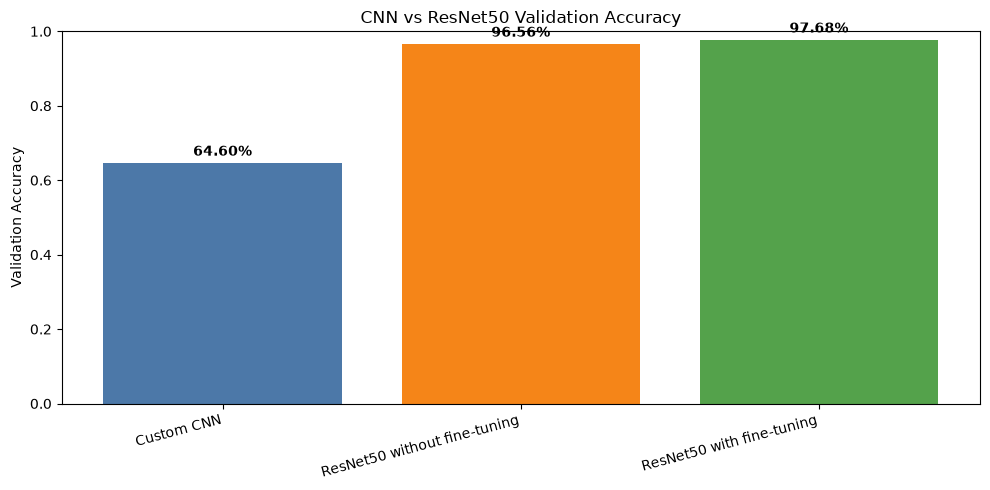

In [ ]:
# Final validation accuracy comparison
comparison = pd.DataFrame({
    "Model": [
        "Custom CNN",
        "ResNet50 without fine-tuning",
        "ResNet50 with fine-tuning",
    ],
    "Validation Accuracy": [
        acc_cnn,
        acc_resnet,
        acc_resnet_finetune,
    ],
})

comparison["Validation Accuracy"] = comparison["Validation Accuracy"].astype(float)
comparison["Validation Accuracy (%)"] = (
    comparison["Validation Accuracy"] * 100
).round(2)

print(comparison[["Model", "Validation Accuracy (%)"]].to_string(index=False))

plt.figure(figsize=(10, 5))
bars = plt.bar(
    comparison["Model"],
    comparison["Validation Accuracy"],
    color=["#4C78A8", "#F58518", "#54A24B"],
)
plt.ylim(0, 1)
plt.ylabel("Validation Accuracy")
plt.title("CNN vs ResNet50 Validation Accuracy")
plt.xticks(rotation=15, ha="right")

for bar, accuracy in zip(bars, comparison["Validation Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.02,
        f"{accuracy:.2%}",
        ha="center",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()